# Feature Engineering for Airline Ticket Prices

This notebook explores how to prepare airline ticket data and create useful features for understanding and later predicting ticket prices. It follows the supplied Skills Network lab while adapting its workflow for a local Python and Jupyter environment.

The dataset contains flight listings from March through June 2019. `Price` is the fare and will be treated as the target variable when we discuss modeling. We will first inspect the source data; feature transformations come in later sections.

**Dataset source:** [Airline ticket data (`airlines_data.xlsx`)](https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML0232EN-SkillsNetwork/asset/airlines_data.xlsx)

## 1. Setup and inspect the dataset

This project uses its own `.venv`, separate from the gasoline analysis environment. Install the packages from this project folder with `python -m pip install -r requirements.txt`, then select this environment as the notebook kernel in VS Code.

The data-acquisition cell downloads `airlines_data.xlsx` into `data/` when it is missing. It uses the local file on later runs and does not overwrite it.

### Legacy warning suppression from the reference lab

The source lab replaces `warnings.warn` with a no-op to hide warnings from older scikit-learn versions. This suppresses **all Python warnings in the current kernel**, not only scikit-learn warnings, and may hide useful compatibility or data-quality messages. It is retained here to match the reference; for ordinary analysis, leave warnings enabled. Restart the kernel to restore the normal warning behavior after running this cell.

In [1]:
# Legacy warning suppression from the reference lab.
def warn(*args, **kwargs):
    pass

import warnings
warnings.warn = warn

### Import the required libraries

This cell imports the packages used throughout the notebook: pandas and NumPy for data work, Matplotlib, Seaborn, and Plotly Express for visualizations, and scikit-learn tools for scaling and PCA. `Path` will help locate the local dataset. The final line expands pandas' displayed columns so wide tables are easier to inspect.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import requests
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 50)

These imports support the notebook's planned work: pandas and NumPy for data handling; Matplotlib, Seaborn, and Plotly Express for charts; and scikit-learn's scaler and PCA tools for a later section. `Path` helps locate the workbook. The `openpyxl` dependency lets pandas read Excel files.

### Download and load the dataset

The path check supports running from the notebook folder, this project folder, or the top-level `ml-journey` folder in VS Code. If the workbook is missing, `requests` downloads it from the source URL into this project’s `data/` folder. The cell checks the HTTP response and keeps any existing local workbook unchanged. Pandas then reads the Excel file, and `head()` previews the first five rows.

In [3]:
working_directory = Path.cwd()
project_candidates = [
    working_directory,
    working_directory.parent,
    working_directory / "projects" / "airline-feature-engineering",
]
project_root = next(
    (
        candidate
        for candidate in project_candidates
        if (candidate / "notebooks").is_dir() and (candidate / "data").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the airline project folders. Open this notebook from "
        "the ml-journey repository in VS Code and try again."
    )

airline_data_path = project_root / "data" / "airlines_data.xlsx"
data_source_url = (
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
    "IBM-ML0232EN-SkillsNetwork/asset/airlines_data.xlsx"
)
airline_data_path.parent.mkdir(parents=True, exist_ok=True)

if not airline_data_path.is_file():
    print("Downloading the airline dataset...")
    response = requests.get(data_source_url, timeout=60)
    response.raise_for_status()
    if not response.content:
        raise ValueError("The dataset download returned an empty file.")
    airline_data_path.write_bytes(response.content)
else:
    print(f"Using the existing dataset at {airline_data_path}")

data = pd.read_excel(airline_data_path, engine="openpyxl")
data.head()

Using the existing dataset at /Users/apple/Documents/ml-journey/projects/airline-feature-engineering/data/airlines_data.xlsx


       Airline Date_of_Journey    Source Destination                  Route  \
0       IndiGo      24/03/2019  Banglore   New Delhi              BLR → DEL   
1    Air India       1/05/2019   Kolkata    Banglore  CCU → IXR → BBI → BLR   
2  Jet Airways       9/06/2019     Delhi      Cochin  DEL → LKO → BOM → COK   
3       IndiGo      12/05/2019   Kolkata    Banglore        CCU → NAG → BLR   
4       IndiGo      01/03/2019  Banglore   New Delhi        BLR → NAG → DEL   

  Dep_Time  Arrival_Time Duration Total_Stops Additional_Info  Price  
0    22:20  01:10 22 Mar   2h 50m    non-stop         No info   3897  
1    05:50         13:15   7h 25m     2 stops         No info   7662  
2    09:25  04:25 10 Jun      19h     2 stops         No info  13882  
3    18:05         23:30   5h 25m      1 stop         No info   6218  
4    16:50         21:35   4h 45m      1 stop         No info  13302  

**Observation:** The workbook loaded successfully. The preview shows flight details such as airline, journey date, route, duration, stops, and a numeric `Price` value. The displayed rows are only a sample; we will inspect the full dataset next.

The preview lets us confirm that the workbook loaded and inspect its actual column names and sample values before relying on the reference notebook's assumptions.

### Dataset dimensions and schema

`shape` reports the row and column counts. `columns` lists the exact labels in the workbook. `info()` shows each column's data type and how many values are present.

In [4]:
data.shape

(10683, 11)

**Observation:** The dataset contains **10,683 rows and 11 columns**. Each row represents a flight listing, and each column records one field about that listing.

In [5]:
data.columns.to_list()

['Airline',
 'Date_of_Journey',
 'Source',
 'Destination',
 'Route',
 'Dep_Time',
 'Arrival_Time',
 'Duration',
 'Total_Stops',
 'Additional_Info',
 'Price']

**Observation:** The workbook has 11 columns, including categorical flight details, time and duration fields, and `Price`. The target column is spelled `Price`, so later code should use that exact label.

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 918.2 KB


**Observation:** Ten columns are stored as strings and `Price` is stored as an integer. `Route` and `Total_Stops` each have 10,682 non-missing values; all other columns have 10,683. We will decide how to handle those two missing records after inspecting them.

### Numeric summary and missing values

`describe()` summarizes the numeric columns. `isna().sum()` counts missing entries in each column. We will use these results to guide cleaning later; we will not fill missing values until we have examined what they mean.

In [7]:
data.describe()

              Price
count  10683.000000
mean    9087.064121
std     4611.359167
min     1759.000000
25%     5277.000000
50%     8372.000000
75%    12373.000000
max    79512.000000

**Observation:** The `Price` column has 10,683 values. Its mean is about **9,087**, its median is **8,372**, and its values range from **1,759** to **79,512**. The maximum is far above the 75th percentile (12,373), so a small number of fares may be substantially higher than most; we can examine the distribution later.

In [8]:
data.isna().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

**Observation:** There is one missing value in `Route` and one in `Total_Stops`; the other nine columns have none. These missing values occur in different columns, so we should inspect their rows before choosing a cleaning approach.

The fare column in the reference dataset is named `Price`. We will treat it as the target in later modeling discussions. This opening section only inspects the raw data; it does not remove rows or fill missing values.

### Forward-fill missing values

The reference lab uses forward fill: each missing value is replaced by the most recent non-missing value above it in the same column. This demonstrates `ffill()`, but it assumes the previous row is a sensible substitute. Since each row is a separate flight listing, that assumption may not be appropriate for a final analysis; we will follow the exercise here and inspect the resulting missing-value counts.

In [9]:
data = data.ffill()
data.isna().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

**Observation:** Forward fill leaves **zero missing values in every column**. It filled the missing `Route` and `Total_Stops` entries using the preceding non-missing values; as noted above, that mechanical fill may not represent the actual details of those individual flights.

## 2. Feature transformation

Feature transformation changes or represents existing data in a form that is more useful for analysis and machine learning. Common examples include encoding categories, scaling numeric values, and discretizing continuous values into bins.

### Dealing with categorical variables

Categorical variables describe groups or labels rather than quantities. Many machine-learning algorithms require these categories to be encoded numerically. Before choosing an encoding method, we will inspect the distinct values in the `Airline` column.

In [10]:
data['Airline'].unique().tolist()

['IndiGo',
 'Air India',
 'Jet Airways',
 'SpiceJet',
 'Multiple carriers',
 'GoAir',
 'Vistara',
 'Air Asia',
 'Vistara Premium economy',
 'Jet Airways Business',
 'Multiple carriers Premium economy',
 'Trujet']

**Observation:** The `Airline` column contains **12 distinct labels** before consolidation. The list includes separate business or premium labels for Jet Airways, Vistara, and Multiple carriers.

Some category labels describe premium or business variants of an airline. To make these labels consistent for this exercise, we will map `Vistara Premium economy` to `Vistara` and `Jet Airways Business` to `Jet Airways`. `np.where(condition, value_if_true, value_if_false)` applies each replacement wherever its condition is true.

In [11]:
data['Airline'] = np.where(data['Airline'] == 'Vistara Premium economy', 'Vistara', data['Airline'])
data['Airline'] = np.where(data['Airline'] == 'Jet Airways Business', 'Jet Airways', data['Airline'])

Display the distinct airline labels again to inspect the recoding.

In [12]:
data['Airline'].unique().tolist()

['IndiGo',
 'Air India',
 'Jet Airways',
 'SpiceJet',
 'Multiple carriers',
 'GoAir',
 'Vistara',
 'Air Asia',
 'Multiple carriers Premium economy',
 'Trujet']

**Observation:** After consolidating the Vistara and Jet Airways variants, the column contains **10 distinct airline labels**. The corresponding variant labels no longer appear separately.

To keep airline categories consistent, we will group `Multiple carriers Premium economy` under `Multiple carriers`. The cell applies this replacement and displays the updated distinct labels.

In [13]:
data['Airline'] = np.where(data['Airline']=='Multiple carriers Premium economy', 'Multiple carriers', data['Airline'])
data['Airline'].unique().tolist()

['IndiGo',
 'Air India',
 'Jet Airways',
 'SpiceJet',
 'Multiple carriers',
 'GoAir',
 'Vistara',
 'Air Asia',
 'Trujet']

**Observation:** After consolidating the Multiple carriers premium variant as well, **9 distinct airline labels** remain.

### One-hot encoding

Many machine-learning algorithms need categorical inputs represented numerically. One-hot encoding creates a separate indicator column for each observed category. Here, we use `pandas.get_dummies()` to encode `Airline`, `Source`, and `Destination`, keeping the result in a new DataFrame named `data1` so the original `data` remains available for comparison. See the [scikit-learn OneHotEncoder documentation](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) for another common implementation.

In [14]:
data1 = pd.get_dummies(data=data, columns=['Airline', 'Source', 'Destination'])
data1.head()

  Date_of_Journey                  Route Dep_Time  Arrival_Time Duration  \
0      24/03/2019              BLR → DEL    22:20  01:10 22 Mar   2h 50m   
1       1/05/2019  CCU → IXR → BBI → BLR    05:50         13:15   7h 25m   
2       9/06/2019  DEL → LKO → BOM → COK    09:25  04:25 10 Jun      19h   
3      12/05/2019        CCU → NAG → BLR    18:05         23:30   5h 25m   
4      01/03/2019        BLR → NAG → DEL    16:50         21:35   4h 45m   

  Total_Stops Additional_Info  Price  Airline_Air Asia  Airline_Air India  \
0    non-stop         No info   3897             False              False   
1     2 stops         No info   7662             False               True   
2     2 stops         No info  13882             False              False   
3      1 stop         No info   6218             False              False   
4      1 stop         No info  13302             False              False   

   Airline_GoAir  Airline_IndiGo  Airline_Jet Airways  \
0          False       

**Observation:** The preview shows the three selected categorical columns represented by Boolean indicator columns. For each displayed row, the matching airline, source, and destination indicators are `True`; the other indicators in those groups are `False`.

Compare the dimensions before and after encoding. The encoded DataFrame should have more columns because each distinct category is represented by its own indicator column. The exact number depends on the categories present in this dataset.

In [15]:
data.shape

(10683, 11)

**Observation:** The original `data` DataFrame remains at **10,683 rows and 11 columns**; one-hot encoding was stored separately in `data1`.

In [16]:
data1.shape

(10683, 28)

**Observation:** `data1` has **10,683 rows and 28 columns**, an increase of 17 columns. The three categorical fields were replaced by 20 category indicators (9 airline, 5 source, and 6 destination categories).

### Distribution of the number of stops

Count how many flight listings fall into each `Total_Stops` category. By default, `value_counts()` sorts the counts from highest to lowest and omits missing values.

In [17]:
data["Total_Stops"].value_counts()

Total_Stops
1 stop      5625
non-stop    3492
2 stops     1520
3 stops       45
4 stops        1
Name: count, dtype: int64

**Observation:** The dataset contains 5,625 listings with one stop, 3,492 non-stop listings, 1,520 with two stops, 45 with three stops, and 1 with four stops. One-stop flights are the most common category, and the counts sum to 10,683 after forward-filling the missing value.

### Label-encode the number of stops

`Total_Stops` has a natural order, so we can represent its categories with increasing integers: `non-stop` as 0, `1 stop` as 1, and so on. We apply the replacements only to the `Total_Stops` column in `data1` and cast the result to an integer dtype so numeric analyses can use it. The preview shows the transformed data.

In [18]:
stop_mapping = {
    'non-stop': 0,
    '1 stop': 1,
    '2 stops': 2,
    '3 stops': 3,
    '4 stops': 4,
}
data1['Total_Stops'] = data1['Total_Stops'].replace(stop_mapping).astype(int)
data1.head()

  Date_of_Journey                  Route Dep_Time  Arrival_Time Duration  \
0      24/03/2019              BLR → DEL    22:20  01:10 22 Mar   2h 50m   
1       1/05/2019  CCU → IXR → BBI → BLR    05:50         13:15   7h 25m   
2       9/06/2019  DEL → LKO → BOM → COK    09:25  04:25 10 Jun      19h   
3      12/05/2019        CCU → NAG → BLR    18:05         23:30   5h 25m   
4      01/03/2019        BLR → NAG → DEL    16:50         21:35   4h 45m   

   Total_Stops Additional_Info  Price  Airline_Air Asia  Airline_Air India  \
0            0         No info   3897             False              False   
1            2         No info   7662             False               True   
2            2         No info  13882             False              False   
3            1         No info   6218             False              False   
4            1         No info  13302             False              False   

   Airline_GoAir  Airline_IndiGo  Airline_Jet Airways  \
0          False 

**Observation:** In the preview, `Total_Stops` is represented numerically: `non-stop` becomes 0, `2 stops` becomes 2, and `1 stop` becomes 1. The mapping preserves the natural order of the stop-count categories.

## 3. Date and time transformations

### Convert flight duration to minutes

The `Duration` column stores elapsed flight time as text, such as hours and minutes. We normalize entries that contain only hours or only minutes, extract the two numeric components, and create a total duration in minutes. `Duration_hours` is multiplied by 60 before it is added to `Duration_minutes`; the resulting `Duration_Total_mins` column is the full elapsed time in minutes. The final expression previews the new columns.

In [19]:
duration = list(data1['Duration'])
for i in range(len(duration)):
    if len(duration[i].split()) != 2:
        if 'h' in duration[i]:
            duration[i] = duration[i].strip() + ' 0m'
        elif 'm' in duration[i]:
            duration[i] = '0h {}'.format(duration[i].strip())

dur_hours = []
dur_minutes = []

for i in range(len(duration)):
    dur_hours.append(int(duration[i].split()[0][:-1]))
    dur_minutes.append(int(duration[i].split()[1][:-1]))

data1['Duration_hours'] = dur_hours
data1['Duration_minutes'] = dur_minutes
data1['Duration_hours'] *= 60
data1['Duration_Total_mins'] = data1['Duration_hours'] + data1['Duration_minutes']

data1.head()

  Date_of_Journey                  Route Dep_Time  Arrival_Time Duration  \
0      24/03/2019              BLR → DEL    22:20  01:10 22 Mar   2h 50m   
1       1/05/2019  CCU → IXR → BBI → BLR    05:50         13:15   7h 25m   
2       9/06/2019  DEL → LKO → BOM → COK    09:25  04:25 10 Jun      19h   
3      12/05/2019        CCU → NAG → BLR    18:05         23:30   5h 25m   
4      01/03/2019        BLR → NAG → DEL    16:50         21:35   4h 45m   

   Total_Stops Additional_Info  Price  Airline_Air Asia  Airline_Air India  \
0            0         No info   3897             False              False   
1            2         No info   7662             False               True   
2            2         No info  13882             False              False   
3            1         No info   6218             False              False   
4            1         No info  13302             False              False   

   Airline_GoAir  Airline_IndiGo  Airline_Jet Airways  \
0          False 

**Observation:** The first five total durations are **170, 445, 1,140, 325, and 285 minutes**. The `19h` entry is normalized to 19 hours and 0 minutes, producing 1,140 total minutes. After multiplication, `Duration_hours` itself stores minutes, as its name may otherwise suggest differently.

### Extract departure hour and minute

`Dep_Time` contains clock times in `HH:MM` format. Parse it with that explicit format, then use the datetime `.dt` accessor to create numeric hour and minute features. The preview shows the original value beside the extracted values.

In [20]:
departure_time = pd.to_datetime(data1['Dep_Time'], format='%H:%M')
data1['Dep_Hour'] = departure_time.dt.hour
data1['Dep_Min'] = departure_time.dt.minute
data1[['Dep_Time', 'Dep_Hour', 'Dep_Min']].head()

  Dep_Time  Dep_Hour  Dep_Min
0    22:20        22       20
1    05:50         5       50
2    09:25         9       25
3    18:05        18        5
4    16:50        16       50

**Observation:** The departure strings were split into numeric hour and minute values; for example, `22:20` becomes hour 22 and minute 20, while `05:50` becomes hour 5 and minute 50.

### Extract arrival hour and minute

Some `Arrival_Time` values include both a clock time and an arrival date. We only need the clock time for these features, so we parse the first five characters (`HH:MM`) with an explicit format. This step creates hour and minute columns while leaving the original `Arrival_Time` values intact.

In [21]:
arrival_time = pd.to_datetime(data1['Arrival_Time'].str[:5], format='%H:%M')
data1['Arrival_Hour'] = arrival_time.dt.hour
data1['Arrival_Min'] = arrival_time.dt.minute
data1[['Arrival_Time', 'Arrival_Hour', 'Arrival_Min']].head()

   Arrival_Time  Arrival_Hour  Arrival_Min
0  01:10 22 Mar             1           10
1         13:15            13           15
2  04:25 10 Jun             4           25
3         23:30            23           30
4         21:35            21           35

**Observation:** The arrival clock times were extracted correctly even when the original value also included a date. For example, `01:10 22 Mar` becomes hour 1 and minute 10.

### Group departure times by time of day

To make departure times easier to compare, group the hour into four intervals: Night (00:00–05:59), Morning (06:00–11:59), Afternoon (12:00–17:59), and Evening (18:00–23:59). We set `right=False` so each interval includes its starting hour; this also assigns hour 0 to Night. The preview shows the hour and its group.

In [22]:
time_bins = [0, 6, 12, 18, 24]
time_labels = ['Night', 'Morning', 'Afternoon', 'Evening']
data1['dep_timezone'] = pd.cut(
    data1['Dep_Hour'],
    bins=time_bins,
    labels=time_labels,
    right=False,
)
data1[['Dep_Hour', 'dep_timezone']].head()

   Dep_Hour dep_timezone
0        22      Evening
1         5        Night
2         9      Morning
3        18      Evening
4        16    Afternoon

**Observation:** The departure preview assigns hour 22 to Evening, hour 5 to Night, hour 9 to Morning, and hour 16 to Afternoon. The selected intervals include midnight in the Night group.

Apply the same intervals to `Arrival_Hour` to create the arrival time-of-day group. We reuse the numeric hour derived in the previous section and keep the original arrival-time field unchanged.

In [23]:
data1['arr_timezone'] = pd.cut(
    data1['Arrival_Hour'],
    bins=time_bins,
    labels=time_labels,
    right=False,
)
data1[['Arrival_Hour', 'arr_timezone']].head()

   Arrival_Hour arr_timezone
0             1        Night
1            13    Afternoon
2             4        Night
3            23      Evening
4            21      Evening

**Observation:** The arrival preview assigns hours 1 and 4 to Night, 13 to Afternoon, and 21 and 23 to Evening. The same time-of-day intervals are applied to arrivals and departures.

### Extract calendar features from the journey date

`Date_of_Journey` is stored as text in day/month/year order. Parse it once with the explicit `%d/%m/%Y` format to avoid ambiguity, then use the resulting datetime values to derive numeric month, day, and year features, as well as the weekday name.

In [24]:
journey_date = pd.to_datetime(data1['Date_of_Journey'], format='%d/%m/%Y')
data1['Month'] = journey_date.dt.month
data1[['Date_of_Journey', 'Month']].head()

  Date_of_Journey  Month
0      24/03/2019      3
1       1/05/2019      5
2       9/06/2019      6
3      12/05/2019      5
4      01/03/2019      3

**Observation:** The displayed dates map to numeric months correctly: March is `3`, May is `5`, and June is `6`. The source strings remain in `Date_of_Journey`; `Month` is a separate numeric feature.

In [25]:
data1['Day'] = journey_date.dt.day
data1['Year'] = journey_date.dt.year
data1[['Date_of_Journey', 'Day', 'Year']].head()

  Date_of_Journey  Day  Year
0      24/03/2019   24  2019
1       1/05/2019    1  2019
2       9/06/2019    9  2019
3      12/05/2019   12  2019
4      01/03/2019    1  2019

**Observation:** The first five journey dates are all in **2019**. Their extracted day values are 24, 1, 9, 12, and 1, matching the day/month/year date format.

In [26]:
data1['day_of_week'] = journey_date.dt.day_name()
data1[['Date_of_Journey', 'day_of_week']].head()

  Date_of_Journey day_of_week
0      24/03/2019      Sunday
1       1/05/2019   Wednesday
2       9/06/2019      Sunday
3      12/05/2019      Sunday
4      01/03/2019      Friday

**Observation:** The displayed weekday names correspond to the parsed dates: Sunday, Wednesday, Sunday, Sunday, and Friday. `day_of_week` is a categorical text feature, while Month, Day, and Year are numeric calendar features.

## 4. Feature selection

We will create a focused DataFrame containing the transformed features selected for this correlation analysis and the target, `Price`. We will leave out the original route text, additional-information text, and other original categorical fields. The correlation heatmap will include numeric and Boolean columns. `dep_timezone` is categorical and will be omitted by `numeric_only=True` unless it is encoded separately; `Total_Stops` is cast to an integer in the label-encoding step so it is included.

Inspect the complete list of columns in the transformed DataFrame before selecting the features.

In [27]:
data1.columns

Index(['Date_of_Journey', 'Route', 'Dep_Time', 'Arrival_Time', 'Duration',
       'Total_Stops', 'Additional_Info', 'Price', 'Airline_Air Asia',
       'Airline_Air India', 'Airline_GoAir', 'Airline_IndiGo',
       'Airline_Jet Airways', 'Airline_Multiple carriers', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Source_Banglore',
       'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai',
       'Destination_Banglore', 'Destination_Cochin', 'Destination_Delhi',
       'Destination_Hyderabad', 'Destination_Kolkata', 'Destination_New Delhi',
       'Duration_hours', 'Duration_minutes', 'Duration_Total_mins', 'Dep_Hour',
       'Dep_Min', 'Arrival_Hour', 'Arrival_Min', 'dep_timezone',
       'arr_timezone', 'Month', 'Day', 'Year', 'day_of_week'],
      dtype='str')

**Observation:** The transformed DataFrame has **41 columns** at this point, including the original fields, encoded categories, and engineered duration, time, and journey-date features. We will select a smaller subset for the correlation analysis.

In [28]:
new_data = data1.loc[:,['Total_Stops', 'Airline_Air Asia',
       'Airline_Air India', 'Airline_GoAir', 'Airline_IndiGo',
       'Airline_Jet Airways', 'Airline_Multiple carriers', 'Airline_SpiceJet',
       'Airline_Trujet', 'Airline_Vistara', 'Source_Banglore',
       'Source_Chennai', 'Source_Delhi', 'Source_Kolkata', 'Source_Mumbai',
       'Destination_Banglore', 'Destination_Cochin', 'Destination_Delhi',
       'Destination_Hyderabad', 'Destination_Kolkata', 'Destination_New Delhi',
       'Duration_hours', 'Duration_minutes', 'Duration_Total_mins', 'Dep_Hour',
       'Dep_Min', 'dep_timezone', 'Price']]
new_data.head()

   Total_Stops  Airline_Air Asia  Airline_Air India  Airline_GoAir  \
0            0             False              False          False   
1            2             False               True          False   
2            2             False              False          False   
3            1             False              False          False   
4            1             False              False          False   

   Airline_IndiGo  Airline_Jet Airways  Airline_Multiple carriers  \
0            True                False                      False   
1           False                False                      False   
2           False                 True                      False   
3            True                False                      False   
4            True                False                      False   

   Airline_SpiceJet  Airline_Trujet  Airline_Vistara  Source_Banglore  \
0             False           False            False             True   
1             Fals

**Observation:** The preview contains the selected stop-count, airline, source, destination, duration, departure, and price fields. The one-hot columns display Boolean values. `dep_timezone` remains a categorical feature in this selection.

In [29]:
new_data.shape

(10683, 28)

**Observation:** `new_data` contains **10,683 rows and 28 columns**, including the target `Price`. The rows are retained while the columns are reduced from the full transformed dataset.

### Correlation heatmap

A correlation matrix summarizes pairwise linear relationships among numeric features. The heatmap makes the matrix easier to scan; the annotations show the correlation coefficients. Correlation can highlight patterns for further investigation, but it does not establish causation.

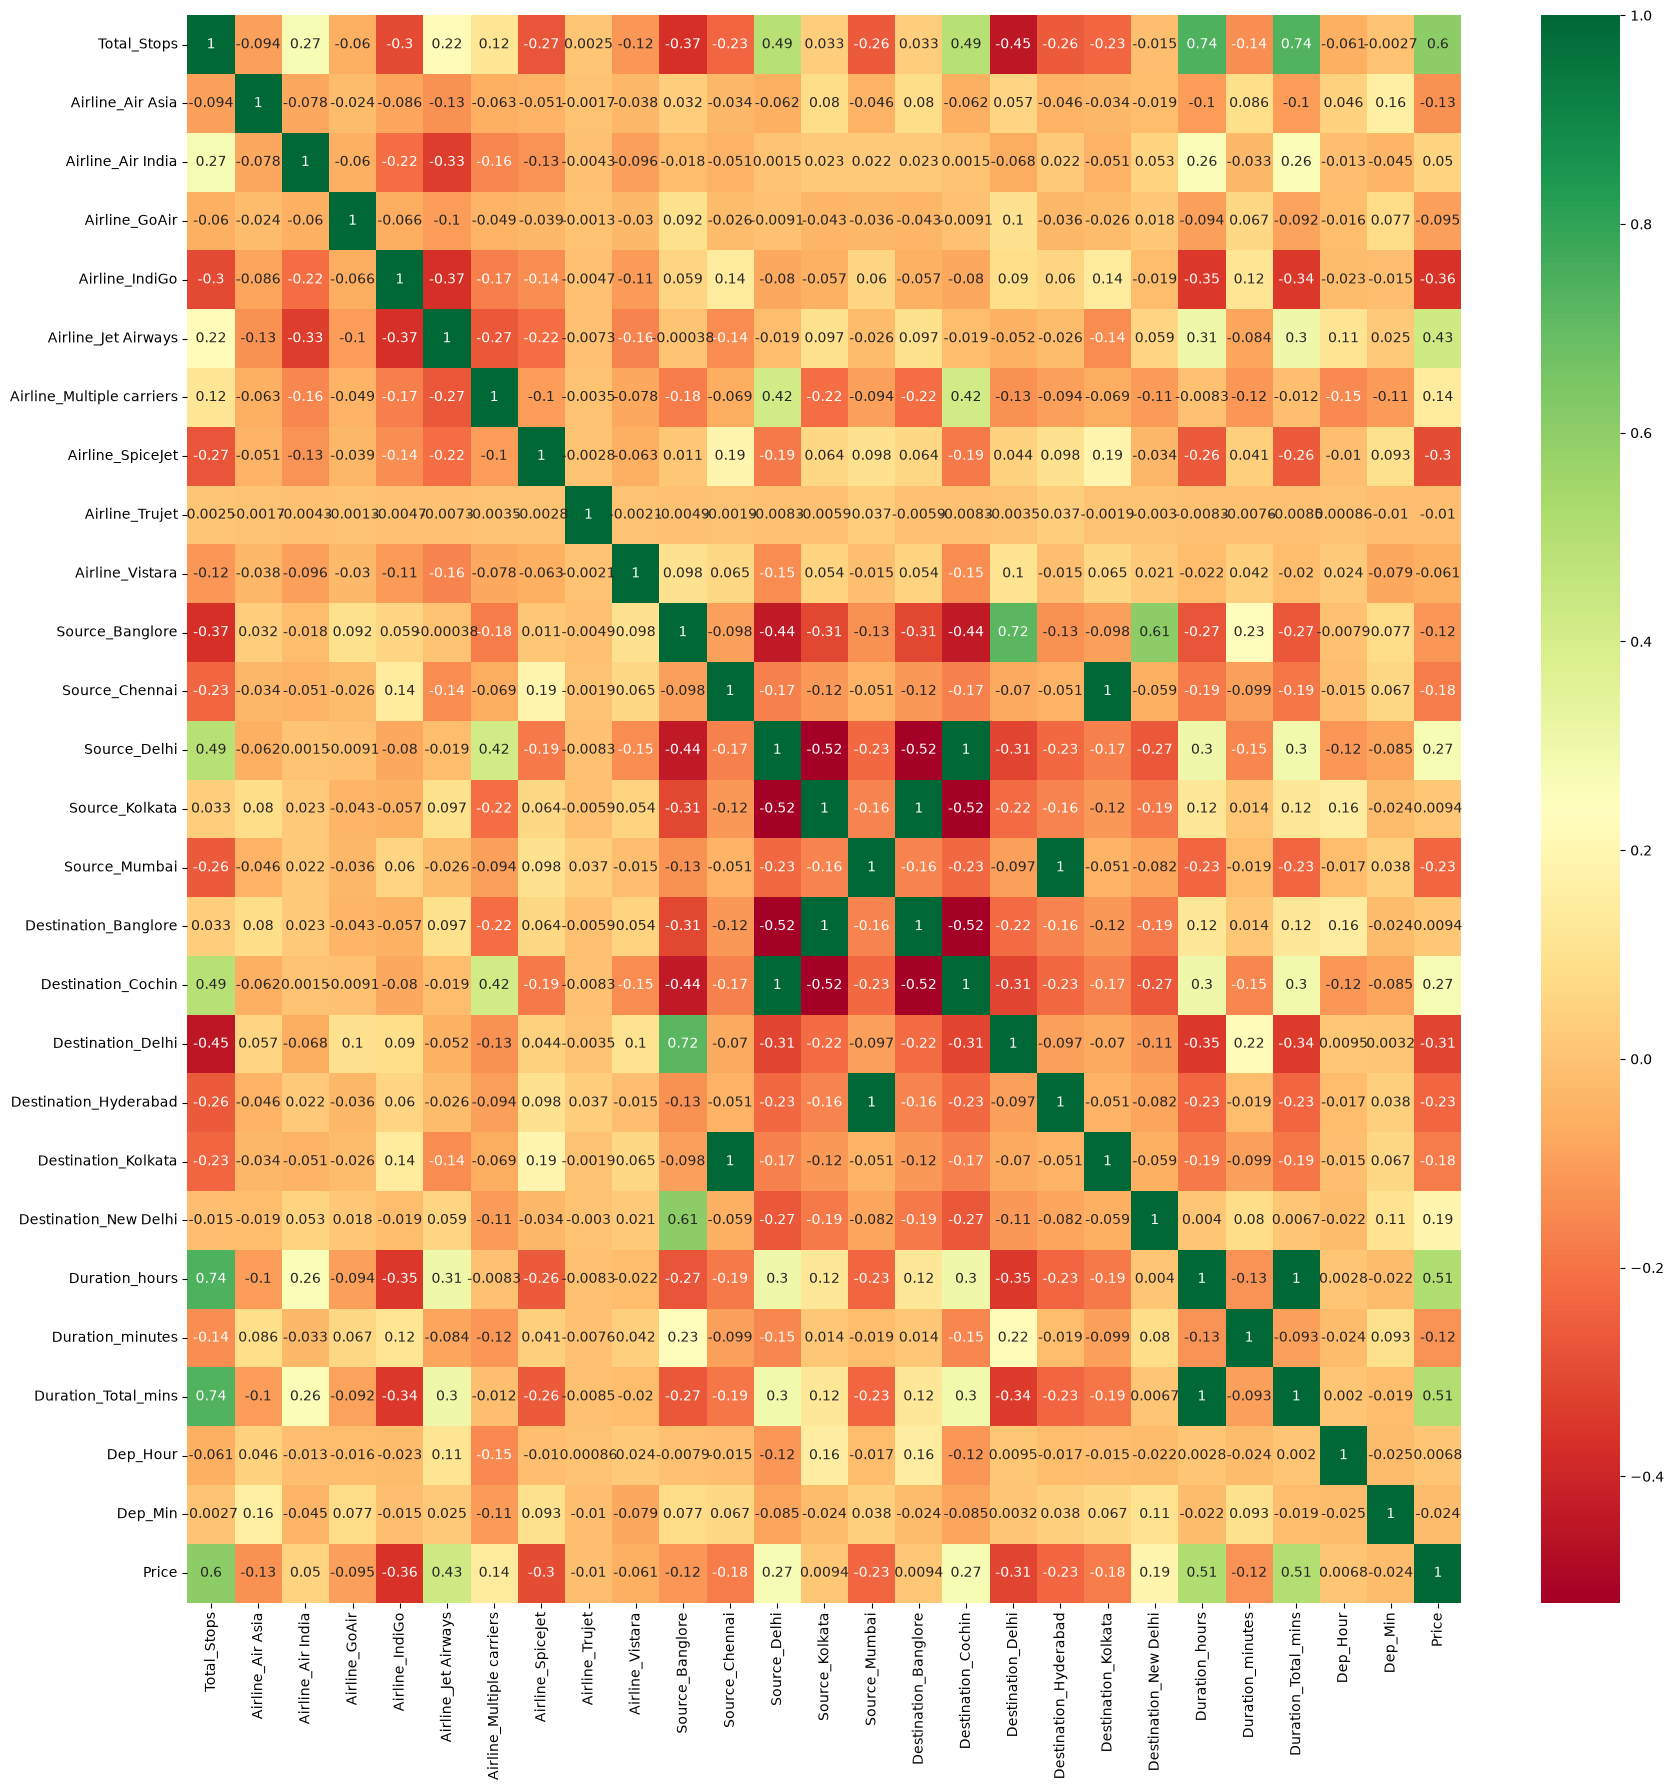

In [30]:
plt.figure(figsize=(18, 18))
sns.heatmap(new_data.corr(numeric_only=True), annot=True, cmap='RdYlGn')
plt.tight_layout()
plt.show()

**Observation:** The heatmap shows a positive correlation between `Total_Stops` and `Price` (about **0.60**) and between flight duration and `Price` (about **0.51**). The `Airline_Jet Airways` indicator has a positive correlation of about **0.43**, while `Airline_IndiGo` has a negative correlation of about **−0.36**. `Duration_hours` and `Duration_Total_mins` are nearly perfectly correlated because they represent the same duration in different units. Some source/destination indicators are also perfectly correlated, which can signal overlapping information. The matrix has 27 columns because categorical `dep_timezone` is excluded by `numeric_only=True`. These values describe associations in this dataset; they do not show that one feature causes a fare to change.


### What the correlation values mean in practice

Each number is a correlation coefficient (`r`) that ranges from **−1 to +1**. A positive value means the two columns tend to be higher together; a negative value means one tends to be higher when the other is lower. Values nearer either end show a stronger *linear* relationship, while values near 0 show a weaker one. A coefficient of **0.60 does not mean a 60% fare increase**.

For example, `Total_Stops` at about **0.60** means flights with more stops tend to have higher fares in these records. Duration at about **0.51** suggests longer flights also tend to have higher fares. These patterns can help an analyst decide which factors to investigate and which features may help a fare-prediction model. The airline values are one-hot indicators: `Airline_Jet Airways` at **0.43** means rows for that airline tend to have higher prices than the overall pattern, while `Airline_IndiGo` at **−0.36** means its rows tend to have lower prices in this dataset. These comparisons can reflect route, date, and other differences as well as airline, so they are not proof of an airline effect.

The near-1 relationship between `Duration_hours` and `Duration_Total_mins` is useful for spotting duplicate information: keeping both may be unnecessary in some models. In real fare analysis, use correlations as an initial screening tool, then check the underlying groups and evaluate features with a model on data it has not seen. Correlation alone cannot establish cause and effect, and it may miss non-linear patterns.

## Correlation of features with ticket price

A heatmap shows relationships between every pair of numeric columns. To focus on the target, `Price`, we can select its column from the correlation matrix and sort the results. This ranks the features from the most negative association to the most positive. The `Price` row itself will also appear with a correlation of 1.0 because a column is perfectly correlated with itself; it is not a model feature.


In [31]:
features = new_data.corr(numeric_only=True)['Price'].sort_values()
features

Airline_IndiGo              -0.361048
Destination_Delhi           -0.313401
Airline_SpiceJet            -0.296552
Destination_Hyderabad       -0.230745
Source_Mumbai               -0.230745
Destination_Kolkata         -0.179216
Source_Chennai              -0.179216
Airline_Air Asia            -0.133044
Duration_minutes            -0.124874
Source_Banglore             -0.118026
Airline_GoAir               -0.095146
Airline_Vistara             -0.060503
Dep_Min                     -0.024492
Airline_Trujet              -0.010380
Dep_Hour                     0.006819
Source_Kolkata               0.009377
Destination_Banglore         0.009377
Airline_Air India            0.050346
Airline_Multiple carriers    0.141087
Destination_New Delhi        0.189785
Destination_Cochin           0.270619
Source_Delhi                 0.270619
Airline_Jet Airways          0.428490
Duration_Total_mins          0.506371
Duration_hours               0.508672
Total_Stops                  0.603891
Price       

**Observation:** The sorted correlations range from **-0.36** for `Airline_IndiGo` to **0.60** for `Total_Stops`. The `Price` value of **1.00** is self-correlation and is not a predictor. For one-hot encoded columns, a positive value means that rows in that category tend to have higher prices than rows outside it; a negative value means they tend to have lower prices. These coefficients describe patterns in this dataset, not percentages or guaranteed effects.


### Interpreting these results

The **0.60** correlation for `Total_Stops` is a positive association: in this sample, flights with a higher encoded number of stops tend to have higher `Price` values. The **−0.36** for `Airline_IndiGo` is a negative association: listings marked as IndiGo tend to have lower prices than listings without that indicator. These values describe broad patterns across the dataset; they do not tell us the fare difference in dollars or rupees.

A reasonable takeaway is that stop count and airline may be useful clues when exploring or predicting fares. They give us questions to investigate—for example, how fares compare across stop counts, and whether the IndiGo pattern remains when comparing similar routes and journey dates. Routes, travel dates, duration, and other factors may explain some of these relationships. The correlations alone cannot tell us which factor caused a fare, or predict the price of a particular ticket.

The **1.00** for `Price` only says that the target is perfectly correlated with itself; it provides no insight about fares and must not be used as an input feature. Treat these results as exploratory evidence and test candidate features in a prediction model before relying on them.


### Visualizing the correlations

The bar chart displays the same coefficients in sorted order, making the direction and relative strength of each feature’s linear association with `Price` easier to compare. Bars below zero indicate negative association; bars above zero indicate positive association.


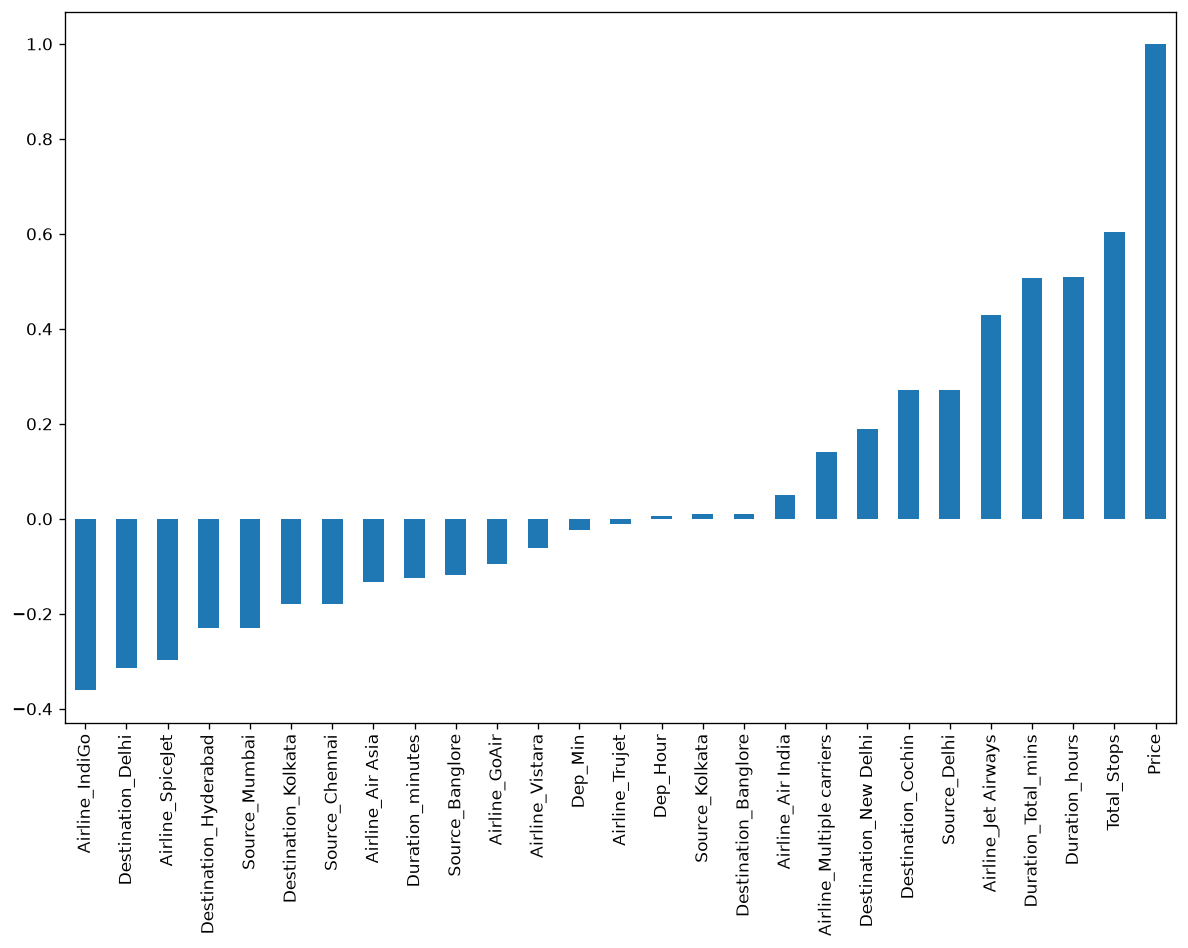

In [32]:
features.plot(kind='bar', figsize=(10, 8))
plt.tight_layout()
plt.show()

**Observation:** The bar chart makes the ranking easier to scan: features on the negative side tend to occur with lower prices in this sample, while features on the positive side tend to occur with higher prices. The size of a bar is a correlation coefficient, not a price change. Use these patterns to decide what to investigate or test in a prediction model; correlation by itself does not establish cause and effect.
